In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
SEED = 407  

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

In [3]:
rng = np.random.default_rng(SEED)
d, sigma = 8, 0.1
Ns = [10, 20, 50, 100, 500]
R, N_test = 500, 1000

w_f = rng.standard_normal(d+1)

def make_data(N, rng):
    X = rng.standard_normal((N, d))
    X = add_bias(X)
    
    noise = sigma * rng.standard_normal(N)
    
    y = X @ w_f + noise
    return X, y

Ein_avg, Eout_avg = [], []
for N in Ns:
    ein, eout = [], []
    for r in range(R):
        X, y = make_data(N, rng)
        w_lin = np.linalg.lstsq(X, y, rcond=None)[0]
        ein.append(mse(y, X @ w_lin))
        
        X_test, y_test = make_data(N_test, rng)
        eout.append(mse(y_test, X_test @ w_lin))
    Ein_avg.append(np.mean(ein))
    Eout_avg.append(np.mean(eout))

In [4]:
df = pd.DataFrame({
    "N": Ns,
    "Ein sim": Ein_avg,
    "Eout sim": Eout_avg,
    "Ein theory": [sigma**2 * (1 - (d + 1) / n) for n in Ns],
    "Eout theory": [sigma**2 * (1 + (d + 1) / n) for n in Ns]
})

df

,N,Ein sim,Eout sim,Ein theory,Eout theory
0,10,0.001005,0.784592,0.00100,0.01900
1,20,0.005528,0.018896,0.00550,0.01450
2,50,0.008198,0.012227,0.00820,0.01180
3,100,0.009075,0.011056,0.00910,0.01090
4,500,0.009781,0.010172,0.00982,0.01018


In [5]:
N_grid = np.arange(d + 2, 501)           
Ein_th  = sigma**2 * (1 - (d + 1) / N_grid)
Eout_th = sigma**2 * (1 + (d + 1) / N_grid)

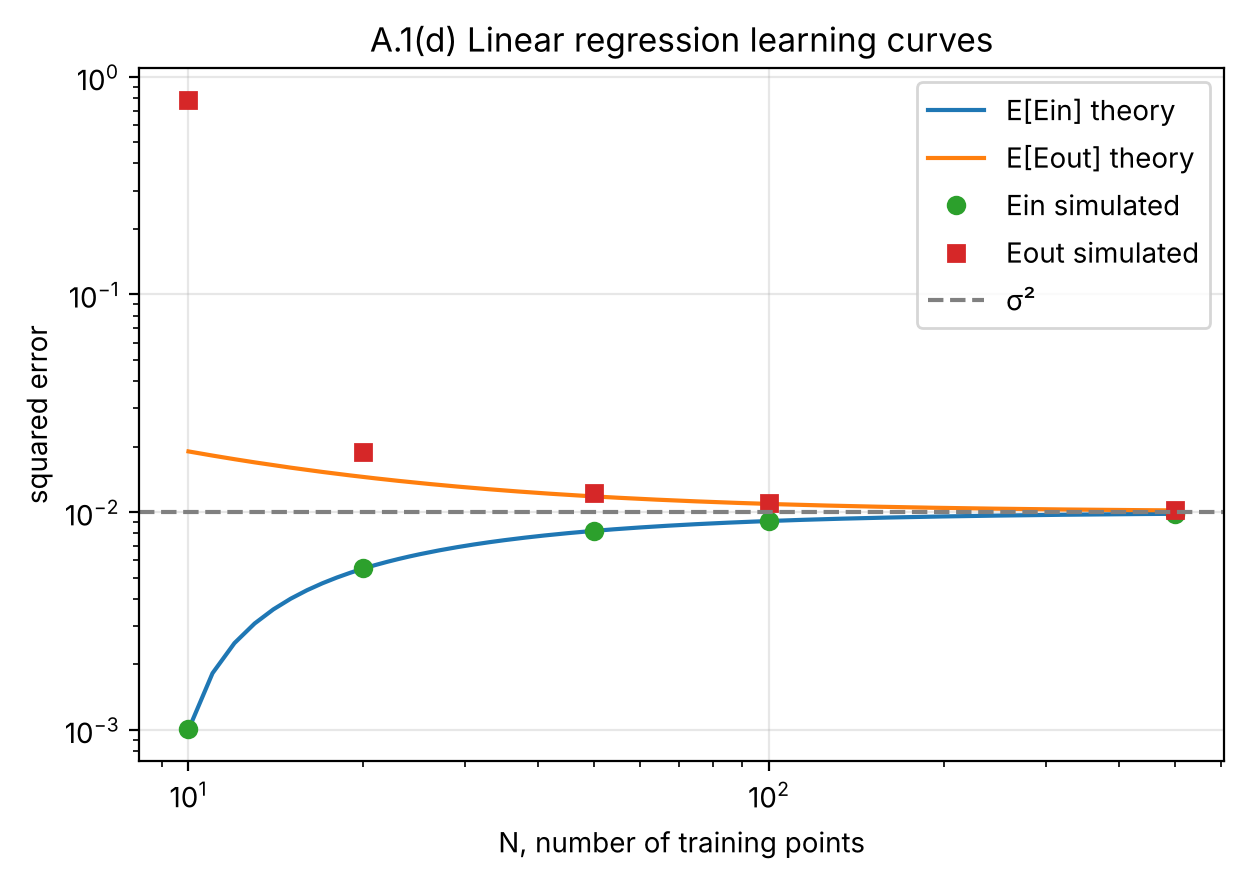

In [6]:
fig, ax = new_ax("N, number of training points", "squared error",
                 "A.1(d) Linear regression learning curves", logx=True, logy=True)
ax.plot(N_grid, Ein_th, "-",  label="E[Ein] theory")
ax.plot(N_grid, Eout_th, "-", label="E[Eout] theory")
ax.plot(Ns, Ein_avg, "o",  label="Ein simulated")
ax.plot(Ns, Eout_avg, "s", label="Eout simulated")
ax.axhline(sigma**2, ls="--", c="gray", label="σ²")
ax.legend(); fig.savefig("A1d.png", dpi=150)